# Step 5: diagnostics, error analysis and insights
**BT4222 Group 5 · Impression-Aware Re-ranking of Search Results on JD.com**

Steps 3 and 4 say how well each model ranks on average. This notebook asks where the final model wins and where it fails, for which users and which items, what drives its ranking, whether its strongest signal could be a leak, and which business ideas the evidence supports. It trains nothing. Every number comes from the scores steps 3 and 4 saved for the test users, the step-2 feature rows and the saved final LightGBM, so it runs on a CPU runtime.

The model studied is the step-4 LightGBM on the kept feature groups (`lgbm_kept`). The blend scored +0.0004 NDCG@10 higher on test, an amount the paired interval could not tell from zero, so the simpler model is the one explained. Sections 2 to 4 compare it with step 4's attention ranker over the split history streams (`attn_split`), the step-3 interim bar (`interim16_lgb`), popularity (`pop_other`) and random ordering. Including the attention ranker shows whether the sequence model helps any group of users or items even though it adds nothing on average.

1. **Where the model wins and loses, by user** (section 2). The test slates are split by what is known before the user acts, and each group gets the paired gain over the bar and over popularity.
2. **Where the positives end up, by item** (section 3). Every clicked, carted or bought candidate is checked for whether it reached the top 10, split by how the user had met the item before, by whether anyone's history holds it, by how widely it is shown and by product category.
3. **Failure cases** (section 4). The slates where no positive reached the top 10 are given one cause each, compared with the rest, and illustrated with three examples.
4. **What drives the ranking** (section 5). SHAP contributions from the saved model are centred within each slate, because only the order inside a slate matters, and set beside the split points the trees learned.
5. **Two checks raised in the group** (sections 6 and 7). Section 6 tests whether "ordered this item before" is the test-day purchase logged twice, and section 7 whether the larger out-of-fold counts for validation and test users bias the model.
6. **Business ideas, tested** (section 8). Three ideas that follow from the diagnostics are scored on the test slates before section 9 states them as insights.

| | |
|---|---|
| **Inputs** | `processed/artifacts/step4/test_scores.parquet`, `lgbm_final.txt` and `lgbm_final.txt.json` (step 4); `processed/results/per_slate/step4_*.parquet` and `step3_*.parquet`, `processed/results/predictions/step3_interim16_lgb.parquet` (steps 3 and 4); `processed/artifacts/features/features_*.parquet`, `model_features.json`, `split_users.parquet` (step 2); `processed/parquet/product_meta_*.parquet` (step 1, for the category view); `processed/artifacts/jd_eval.py` (step 3) |
| **Outputs** | In `processed/results/`, `step5_user_segments.csv`, `step5_item_segments.csv`, `step5_failures.csv`, `step5_failure_causes.csv`, `step5_shap_groups.csv`, `step5_tree_splits.csv`, `step5_shap_features.csv`, `step5_leak_by_age.csv`, `step5_sensitivity.csv`, `step5_business_tests.csv` and `step5_key_numbers.csv`; figures `processed/results/figures/step5_*.png` |
| **Runtime** | CPU, standard RAM. No GPU needed. About 30 minutes for Run all; the SHAP contributions in section 5 take about 24 of them |
| **Next** | None: the last notebook. Its tables and figures go into the final report |

**How to run.** Run steps 3 and 4 first, so their saved files exist, and add a shortcut to the shared `JDsearch_rawData` folder in My Drive. Then choose Runtime → Run all here and save with outputs (File → Save) before committing to GitHub. Every random step uses seed 42, so a re-run gives the same numbers.

## 0. Setup

In [ ]:
import os, sys, glob, json, time, subprocess
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display, HTML

try:
    import lightgbm as lgb
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], check=True)
    import lightgbm as lgb

try:                                   # Colab: mount Drive. Elsewhere: set JD_BASE instead
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

BASE = os.environ.get("JD_BASE", "/content/drive/MyDrive/JDsearch_rawData")
assert os.path.isdir(BASE), f"{BASE} not found: add a shortcut to JDsearch_rawData in My Drive"
PROC = os.path.join(BASE, "processed")
PATHS = {"artifacts": os.path.join(PROC, "artifacts"), "features": os.path.join(PROC, "artifacts", "features"),
         "step4": os.path.join(PROC, "artifacts", "step4"), "results": os.path.join(PROC, "results"),
         "figures": os.path.join(PROC, "results", "figures"), "per_slate": os.path.join(PROC, "results", "per_slate"),
         "predictions": os.path.join(PROC, "results", "predictions")}
os.makedirs(PATHS["figures"], exist_ok=True)

SAVED = {"lgbm": "step4_lgbm_kept__score", "attn": "step4_attn_split__score", "blend": "step4_blend__score", "bar": "step3_interim16_lgb__score",
         "pop": "step3_pop_other__score", "random": "step3_random__score"}
NEEDED = [os.path.join(PATHS["artifacts"], f) for f in ("jd_eval.py", "model_features.json", "split_users.parquet")]
NEEDED += [os.path.join(PATHS["step4"], f) for f in ("test_scores.parquet", "lgbm_final.txt", "lgbm_final.txt.json")]
NEEDED += [os.path.join(PATHS["per_slate"], f"{name}.parquet") for name in SAVED.values()]
NEEDED += [os.path.join(PATHS["predictions"], "step3_interim16_lgb.parquet")]
missing = [os.path.relpath(f, BASE) for f in NEEDED if not os.path.exists(f)]
assert not missing, f"not found: {missing}. Run steps 3 and 4 first"

sys.path.insert(0, PATHS["artifacts"])
sys.modules.pop("jd_eval", None)
import jd_eval as J
assert hasattr(J, "paired"), f"{J.__file__} is not the step-3 evaluation module: run step 3 first"

SMOKE = os.environ.get("JD_SMOKE") == "1"      # tiny settings for a local test run; leave unset on Colab
CFG = {
    "seed": 42,
    "shap_slates": 200 if SMOKE else 3000,
    "examples": 3,
    "leak_days": 1.0,                           # days
}
SEED = CFG["seed"]
N_BOOT = 100 if SMOKE else 1000

MF = json.load(open(os.path.join(PATHS["artifacts"], "model_features.json")))
GROUPS = MF["groups"]
GROUP_OF = {f: g for g, feats in GROUPS.items() for f in feats}
path = os.path.join(PATHS["step4"], "lgbm_final.txt")
LGBM = lgb.Booster(model_file=path)
LGBM.best_iteration = int(json.load(open(path + ".json"))["best_iteration"])
LGBM_FEATS = LGBM.feature_name()
KEPT = sorted({GROUP_OF[f] for f in LGBM_FEATS})
NAMES = {"lgbm": "LightGBM (step 4)", "attn": "Attention ranker (step 4)", "bar": "Interim bar (step 3)",
         "pop": "Popularity (step 3)", "random": "Random"}
COLOURS = {"lgbm": "royalblue", "attn": "seagreen", "bar": "darkorange", "pop": "grey", "random": "silver"}
print(f"evaluation module {J.__file__} | final LightGBM {LGBM.best_iteration} trees on {len(LGBM_FEATS)} features"
      f" in {len(KEPT)} groups" + (" | SMOKE TEST SETTINGS" if SMOKE else ""))

def show_result(title, obj=None, note=""):
    """Red RESULT banner, then the table, so key outputs stand out in the saved notebook."""
    extra = f'<div style="font-size:90%;margin-top:3px">{note}</div>' if note else ""
    display(HTML('<div style="border-left:6px solid #c0392b;background:#fbeaea;color:#1f1f1f;'
                 'padding:8px 12px;margin:12px 0 4px 0;font-family:Arial,sans-serif">'
                 f"<b>RESULT</b> &nbsp;|&nbsp; {title}{extra}</div>"))
    if obj is not None:
        display(obj)

def mark(styler, df, cols):
    """Colour each paired difference green when its interval is above zero and red when below."""
    def colour(col):
        lo, hi = df[f"{col} lo"].to_numpy(), df[f"{col} hi"].to_numpy()
        return ["background-color:lightgreen" if a > 0 else "background-color:lightpink" if b < 0 else "" for a, b in zip(lo, hi)]
    for col in cols:
        styler = styler.apply(lambda _, c=col: colour(c), subset=[col])
    return styler

def save_csv(df, name):
    df.to_csv(os.path.join(PATHS["results"], f"step5_{name}.csv"), index=False)

def save_fig(fig, name):
    fig.savefig(os.path.join(PATHS["figures"], f"step5_{name}.png"), dpi=200, bbox_inches="tight")

Mounted at /content/drive
evaluation module /content/drive/MyDrive/JDsearch_rawData/processed/artifacts/jd_eval.py | final LightGBM 326 trees on 25 features in 6 groups


## 1. Test rows and saved scores
The cell builds one table with a row per test impression, in the same order as step 4 wrote `test_scores.parquet` and step 3 wrote its predictions, so every score lines up with its feature row. The cell checks this, then re-evaluates each model's saved scores with `jd_eval` and checks the per-slate results match the files steps 3 and 4 saved. If they match, every later section measures the same models the report quotes.

Popularity and random are rebuilt exactly as step 3 built them. Popularity counts the users whose history holds the item, minus the user themselves, and random uses step 3's random stream (seed 42 + 7) over the same rows.

In [ ]:
split_users = pd.read_parquet(os.path.join(PATHS["artifacts"], "split_users.parquet"))
TEST_USERS = np.sort(split_users.loc[split_users["split"] == "test", "user_id"].to_numpy().astype(np.int64))
OWN = ["ui_item_days_click", "ui_item_days_cart", "ui_item_days_order"]
COLS = list(dict.fromkeys(["user_id", "wid", "label"] + MF["model_features"] + ["i_pop_any"]))
fparts = sorted(glob.glob(os.path.join(PATHS["features"], "features_*.parquet")))
assert fparts and not [f for f in fparts if " (" in os.path.basename(f)], "features missing or Drive duplicate copies present"
frames = []
for f in fparts:
    d = pd.read_parquet(f, columns=COLS)
    frames.append(d.loc[d["user_id"].isin(TEST_USERS)])
T = pd.concat(frames, ignore_index=True)
del frames, d

sc = pd.read_parquet(os.path.join(PATHS["step4"], "test_scores.parquet"))
bar = pd.read_parquet(os.path.join(PATHS["predictions"], "step3_interim16_lgb.parquet"))
for name, other in (("step 4 test_scores", sc), ("step 3 interim16 predictions", bar)):
    assert len(other) == len(T) and (other["user_id"].to_numpy() == T["user_id"].to_numpy()).all() \
        and (other["wid"].to_numpy() == T["wid"].to_numpy()).all(), f"{name} rows do not line up with the feature rows"

USER = T["user_id"].to_numpy().astype(np.int64)
LABEL = T["label"].to_numpy().astype(np.int64)
COLD = T["i_pop_any"].to_numpy() == 0
OWN_ANY = T[OWN].notna().any(axis=1).to_numpy()
assert (np.diff(USER) >= 0).all(), "rows are not grouped by user"
START = np.r_[0, np.flatnonzero(np.diff(USER)) + 1]
LEN = np.diff(np.r_[START, len(USER)])
SCORE = {"lgbm": sc["lightgbm"].to_numpy(), "attn": sc["attention"].to_numpy(), "blend": sc["blend"].to_numpy(), "bar": bar["score"].to_numpy(),
         "pop": T["i_pop_any"].to_numpy() - OWN_ANY, "random": np.random.default_rng(SEED + 7).random(len(T))}
del sc, bar
PS = {k: J.evaluate(USER, LABEL, s, COLD, seed=SEED) for k, s in SCORE.items()}
assert all((PS[k]["user_id"].to_numpy() == PS["lgbm"]["user_id"].to_numpy()).all() for k in PS)

check = {}
for k, name in SAVED.items():
    saved = pd.read_parquet(os.path.join(PATHS["per_slate"], f"{name}.parquet"))
    m = PS[k][["user_id", "ndcg@10"]].merge(saved[["user_id", "ndcg@10"]], on="user_id", suffixes=("", "_saved"))
    gap = np.abs(m["ndcg@10"] - m["ndcg@10_saved"]).to_numpy()
    check[NAMES.get(k, "Blend (step 4)")] = {"slates": len(m), "NDCG@10 here": PS[k]["ndcg@10"].mean(),
                                            "NDCG@10 saved": saved["ndcg@10"].mean(),
                                            "largest per-slate gap": np.nanmax(gap) if np.isfinite(gap).any() else 0.0}
check = pd.DataFrame(check).T
show_result("Re-scored test results against the files steps 3 and 4 saved", check.round(4))
MATCH = check["largest per-slate gap"] < 1e-6
assert MATCH.drop(NAMES["random"]).all(), "re-evaluated results differ from the saved per-slate files"
EVAL = PS["lgbm"]["ndcg@10"].notna().to_numpy()
print(f"{len(T):,} test impressions in {len(START):,} slates, {EVAL.sum():,} with a positive | cold impressions {COLD.mean():.1%} | "
      + ("every model matches its saved per-slate results" if MATCH.all() else
         "every trained model and popularity match, random does not (step 3 drew it over different rows), so section 2's random column is only indicative"))

,slates,NDCG@10 here,NDCG@10 saved,largest per-slate gap
LightGBM (step 4),17505.0,0.4220,0.4220,0.0
Attention ranker (step 4),17505.0,0.4177,0.4177,0.0
Blend (step 4),17505.0,0.4224,0.4224,0.0
Interim bar (step 3),17505.0,0.4071,0.4071,0.0
Popularity (step 3),17505.0,0.3423,0.3423,0.0
Random,17505.0,0.0800,0.0800,0.0


1,567,024 test impressions in 17,505 slates, 17,297 with a positive | cold impressions 56.5% | every model matches its saved per-slate results


## 2. Where the model wins and loses, by user
Each test slate is put in a group by something known before the user acts, about the user or about the slate, so a ranker could use the same split at serving time. The last split, by the best outcome in the slate, reads the labels and is there only to describe the errors. Inside each group the table gives NDCG@10 for each model and three paired differences with a 95% bootstrap interval over the group's slates, LightGBM against the bar, LightGBM against popularity, and the attention ranker against LightGBM. A difference counts only when its interval excludes zero, the rule steps 3 and 4 used. With about 25 groups, roughly one interval in twenty can exclude zero by chance, so a single surprising group deserves less weight than a pattern across groups. Purchase Recall@10 is given for LightGBM and popularity too, because purchases are what JD earns from.

Random ordering scores very differently on short and long slates, so its column shows how hard each group is before any model is applied.

segment,group,slates,share of slates,LightGBM (step 4),Attention ranker (step 4),Interim bar (step 3),Popularity (step 3),Random,"purchase Recall@10, LightGBM (step 4)","purchase Recall@10, Popularity (step 3)",LightGBM minus bar,LightGBM minus bar lo,LightGBM minus bar hi,LightGBM minus popularity,LightGBM minus popularity lo,LightGBM minus popularity hi,attention minus LightGBM,attention minus LightGBM lo,attention minus LightGBM hi
clicks in the last 7 days,none,"2,820",16.3%,0.3996,0.3984,0.3908,0.3529,0.0814,0.6643,0.5727,0.0088,0.0030,0.0144,0.0467,0.0391,0.0549,-0.0012,-0.0065,0.0040
clicks in the last 7 days,1 to 9,"4,016",23.2%,0.4309,0.4275,0.4207,0.3444,0.0824,0.6893,0.6045,0.0102,0.0055,0.0151,0.0865,0.0783,0.0958,-0.0034,-0.0079,0.0005
clicks in the last 7 days,10 to 49,"5,949",34.4%,0.4331,0.4278,0.4168,0.3448,0.0803,0.6879,0.6332,0.0164,0.0127,0.0201,0.0883,0.0815,0.0947,-0.0053,-0.0087,-0.0019
clicks in the last 7 days,50 or more,"4,512",26.1%,0.4135,0.4076,0.3926,0.3304,0.0767,0.6543,0.5615,0.0209,0.0163,0.0260,0.0831,0.0754,0.0904,-0.0059,-0.0101,-0.0016
orders in the last year,none,"1,462",8.5%,0.4349,0.4324,0.4235,0.3385,0.0930,0.6216,0.5135,0.0115,0.0034,0.0196,0.0964,0.0821,0.1103,-0.0025,-0.0099,0.0047
orders in the last year,1 to 4,"3,249",18.8%,0.4194,0.4165,0.4039,0.3359,0.0808,0.6209,0.5369,0.0155,0.0102,0.0211,0.0835,0.0750,0.0923,-0.0029,-0.0080,0.0016
orders in the last year,5 to 19,"5,020",29.0%,0.4132,0.4082,0.4015,0.3341,0.0800,0.6687,0.5876,0.0117,0.0070,0.0162,0.0790,0.0719,0.0866,-0.0050,-0.0087,-0.0012
orders in the last year,20 or more,"7,566",43.7%,0.4265,0.4216,0.4091,0.3512,0.0773,0.6931,0.6197,0.0174,0.0139,0.0210,0.0753,0.0694,0.0811,-0.0049,-0.0080,-0.0017
ran this exact query before,no,"17,297",100.0%,0.4220,0.4177,0.4071,0.3423,0.0800,0.6758,0.5979,0.0149,0.0126,0.0170,0.0797,0.0759,0.0838,-0.0043,-0.0064,-0.0024
history touches a candidate,no,"12,345",71.4%,0.3909,0.3870,0.3796,0.3549,0.0841,0.6551,0.6168,0.0113,0.0086,0.0140,0.0360,0.0326,0.0396,-0.0039,-0.0066,-0.0016


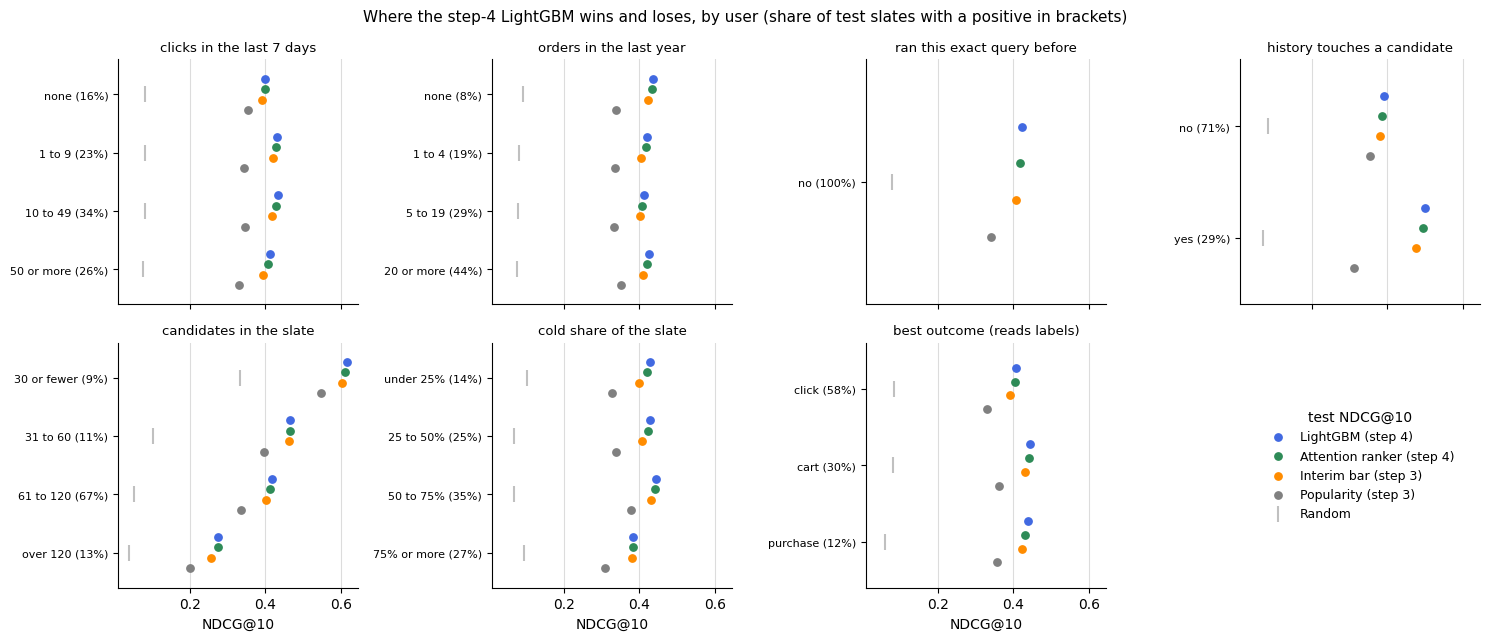

In [ ]:
first = START
SL = pd.DataFrame({"user_id": USER[first], "n": LEN})
for c in ("u_n_click_w", "u_n_order_w", "q_seen_before"):
    SL[c] = T[c].to_numpy()[first]
SL["cold_share"] = np.add.reduceat(COLD.astype(float), first) / LEN
SL["own_any"] = np.maximum.reduceat(OWN_ANY.astype(np.int8), first) > 0
SL["best"] = np.maximum.reduceat(LABEL, first)
assert (SL["user_id"].to_numpy() == PS["lgbm"]["user_id"].to_numpy()).all()

def bins(x, edges, labels):
    return pd.Categorical(pd.cut(x, edges, labels=labels, right=False), categories=labels)

def yes_no(x):
    return pd.Categorical(np.where(x, "yes", "no"), categories=["no", "yes"])

SEGMENTS = {
    "clicks in the last 7 days": bins(SL["u_n_click_w"].fillna(0), [0, 1, 10, 50, np.inf], ["none", "1 to 9", "10 to 49", "50 or more"]),
    "orders in the last year": bins(SL["u_n_order_w"].fillna(0), [0, 1, 5, 20, np.inf], ["none", "1 to 4", "5 to 19", "20 or more"]),
    "ran this exact query before": yes_no(SL["q_seen_before"].fillna(0).to_numpy() > 0),
    "history touches a candidate": yes_no(SL["own_any"].to_numpy()),
    "candidates in the slate": bins(SL["n"], [0, 31, 61, 121, np.inf], ["30 or fewer", "31 to 60", "61 to 120", "over 120"]),
    "cold share of the slate": bins(SL["cold_share"], [0, 0.25, 0.5, 0.75, 1.01], ["under 25%", "25 to 50%", "50 to 75%", "75% or more"]),
    "best outcome (reads labels)": pd.Categorical(SL["best"].map({1: "click", 2: "cart", 3: "purchase"}), categories=["click", "cart", "purchase"]),
}

def diff_cols(row, a, b, label, mask):
    d = J.paired(PS[a].loc[mask], PS[b].loc[mask], "ndcg@10", n_boot=N_BOOT, seed=SEED)
    row[label] = d["diff"]
    row[f"{label} lo"], row[f"{label} hi"] = d["lo"], d["hi"]

seg_rows = []
n_eval = EVAL.sum()
for seg, levels in SEGMENTS.items():
    for level in levels.categories:
        mask = (np.asarray(levels) == level) & EVAL
        if mask.sum() == 0:
            continue
        row = {"segment": seg, "group": level, "slates": int(mask.sum()), "share of slates": mask.sum() / n_eval}
        for k in ("lgbm", "attn", "bar", "pop", "random"):
            row[NAMES[k]] = PS[k].loc[mask, "ndcg@10"].mean()
        for k in ("lgbm", "pop"):
            row[f"purchase Recall@10, {NAMES[k]}"] = PS[k].loc[mask, "purchase_recall@10"].mean()
        diff_cols(row, "lgbm", "bar", "LightGBM minus bar", mask)
        diff_cols(row, "lgbm", "pop", "LightGBM minus popularity", mask)
        diff_cols(row, "attn", "lgbm", "attention minus LightGBM", mask)
        seg_rows.append(row)
SEG = pd.DataFrame(seg_rows)
save_csv(SEG, "user_segments")
with pd.option_context("display.max_rows", 100):
    DIFFS = ["LightGBM minus bar", "LightGBM minus popularity", "attention minus LightGBM"]
    fmt = {c: "{:.4f}" for c in SEG.columns if c not in ("segment", "group", "slates", "share of slates")}
    show_result("Test NDCG@10 by user group, with paired differences and 95% intervals",
                mark(SEG.style.format(fmt | {"share of slates": "{:.1%}", "slates": "{:,}"}, na_rep="-"), SEG, DIFFS).hide(axis="index"),
                note="Green marks an interval above zero and red one below zero. Purchase Recall@10 is averaged over the group's slates with a purchase.")

### Figures
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5), sharex=True)
for ax, (seg, part) in zip(axes.flat, SEG.groupby("segment", sort=False)):
    y = np.arange(len(part))[::-1]
    for k, off in (("lgbm", 0.27), ("attn", 0.09), ("bar", -0.09), ("pop", -0.27)):
        ax.scatter(part[NAMES[k]], y + off, s=28, color=COLOURS[k], label=NAMES[k], zorder=3)
    ax.scatter(part[NAMES["random"]], y, marker="|", s=120, color=COLOURS["random"], label=NAMES["random"], zorder=2)
    ax.set_yticks(y)
    ax.set_ylim(-0.6, len(part) - 0.4)
    ax.set_yticklabels([f"{g} ({s:.0%})" for g, s in zip(part["group"], part["share of slates"])], fontsize=8)
    ax.set_title(seg, fontsize=9.5)
    ax.grid(axis="x", color="gainsboro", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
for ax in axes.flat[SEG["segment"].nunique():]:
    ax.axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False, fontsize=9, title="test NDCG@10")
for ax in axes[-1]:
    ax.set_xlabel("NDCG@10")
fig.suptitle("Where the step-4 LightGBM wins and loses, by user (share of test slates with a positive in brackets)", fontsize=11)
fig.tight_layout()
save_fig(fig, "user_segments")
plt.show()

## 3. Where the positives end up, by item
NDCG is a slate score, so it cannot be split by item. This section follows every candidate the user clicked, carted or bought instead, and asks whether each model put it in the top 10 of its slate. The positives are split by past contact, by whether the item is cold (in no user's history), by how many slates show it, by the outcome, and by its top-level product category (ids are anonymised in the data, so only the largest eight are named and the rest pooled). Ties are broken at random with the same seed `jd_eval` uses, so these ranks are the ones behind the NDCG numbers. The random column is the share a random order would put in the top 10, which is higher on short slates.

**Past contact** is the strongest step the user had taken towards the item inside the history windows (ordered, then carted, then clicked). A candidate with no past contact can still share a shop, brand or category with the history, which is what group H2 measures.

segment,group,positives,share of positives,top 10: LightGBM (step 4),top 10: Attention ranker (step 4),top 10: Interim bar (step 3),top 10: Popularity (step 3),top 10: Random,median rank (LightGBM),median candidates
past contact with the item,ordered before,354,1.1%,98.9%,98.9%,96.9%,65.0%,15.2%,1,89
past contact with the item,carted before,"1,041",3.3%,98.0%,97.2%,96.4%,63.4%,15.0%,1,90
past contact with the item,clicked before,"1,583",5.0%,98.5%,98.9%,97.0%,50.2%,13.9%,1,90
past contact with the item,"no contact, shop/brand/category seen","13,468",42.3%,47.4%,46.9%,46.1%,42.7%,13.9%,12,91
past contact with the item,nothing in the history,"15,358",48.3%,45.4%,45.0%,44.5%,42.7%,13.1%,13,92
item in anyone's history,warm,"23,438",73.7%,64.7%,64.0%,63.4%,57.2%,13.1%,6,91
item in anyone's history,cold (no one),"8,366",26.3%,13.6%,13.9%,12.6%,7.0%,14.8%,43,97
slates showing the item,1,"6,825",21.5%,22.5%,22.6%,22.1%,17.8%,15.7%,38,93
slates showing the item,2 to 5,"7,974",25.1%,39.8%,38.9%,38.1%,29.3%,14.3%,16,93
slates showing the item,6 to 20,"8,686",27.3%,55.8%,55.2%,54.2%,47.6%,12.6%,8,92


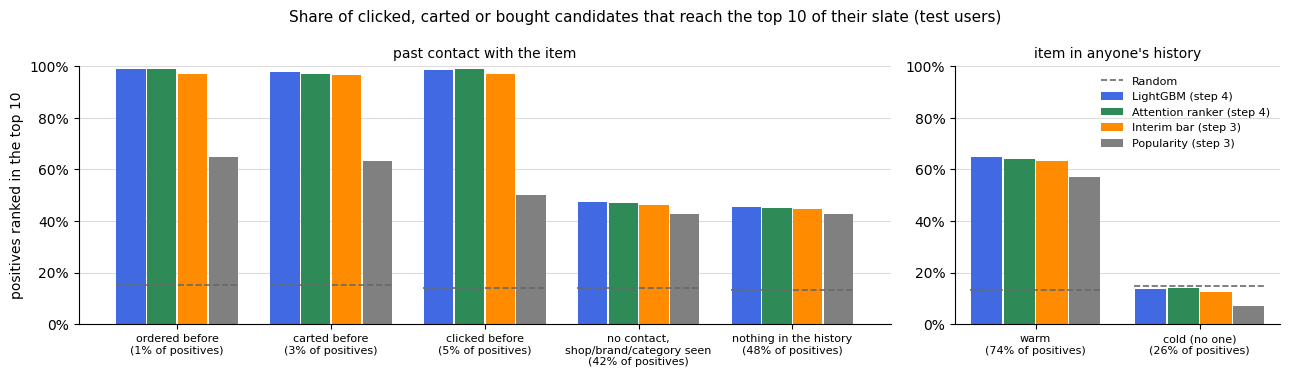

In [ ]:
def slate_rank(score, seed=SEED):
    """0-based rank of every row inside its slate, ties broken at random as in jd_eval."""
    tie = np.random.default_rng(seed).random(len(USER))
    o = np.lexsort((tie, -np.asarray(score, dtype=np.float64), USER))
    rank = np.empty(len(USER), np.int64)
    rank[o] = np.arange(len(USER)) - np.repeat(START, LEN)
    return rank

RANK = {k: slate_rank(SCORE[k]) for k in ("lgbm", "attn", "bar", "pop")}
SLATE_N = np.repeat(LEN, LEN)
POS = LABEL > 0
contact = np.select([T["ui_item_days_order"].notna(), T["ui_item_days_cart"].notna(), T["ui_item_days_click"].notna()],
                    ["ordered before", "carted before", "clicked before"], "no past contact")
h2_cols = [c for c in GROUPS["H2 where a match comes from"] if c in T]
h2_any = T[h2_cols].notna().any(axis=1).to_numpy()
contact = np.where((contact == "no past contact") & h2_any, "no contact, shop/brand/category seen", contact)
contact = np.where(contact == "no past contact", "nothing in the history", contact)
CONTACT_ORDER = ["ordered before", "carted before", "clicked before", "no contact, shop/brand/category seen", "nothing in the history"]
ITEM_SEGMENTS = {
    "past contact with the item": pd.Categorical(contact, categories=CONTACT_ORDER),
    "item in anyone's history": pd.Categorical(np.where(COLD, "cold (no one)", "warm"), categories=["warm", "cold (no one)"]),
    "slates showing the item": bins(T["i_exposure_n"].fillna(0).to_numpy(), [0, 2, 6, 21, 101, np.inf],
                                    ["1", "2 to 5", "6 to 20", "21 to 100", "over 100"]),
    "outcome": pd.Categorical(pd.Series(LABEL).map({1: "click", 2: "cart", 3: "purchase"}), categories=["click", "cart", "purchase"]),
}
meta = sorted(glob.glob(os.path.join(PROC, "parquet", "product_meta_*.parquet")))
if meta:
    pos_wid = np.unique(T["wid"].to_numpy()[POS])
    cat = pd.concat([d[d["wid"].isin(pos_wid)] for d in (pd.read_parquet(f, columns=["wid", "cate_id_1"]) for f in meta)])
    cat = cat.drop_duplicates("wid").set_index("wid")["cate_id_1"]
    c1 = cat.reindex(T["wid"].to_numpy()).fillna(-1).astype(np.int64).to_numpy()
    top = pd.Series(c1[POS & (c1 >= 0)]).value_counts().index[:8]
    names = np.where(np.isin(c1, top), "category " + pd.Series(c1).astype(str).to_numpy(), "all other categories")
    names = np.where(c1 < 0, "no metadata", names)
    ITEM_SEGMENTS["top-level category"] = pd.Categorical(names, categories=[f"category {c}" for c in top] + ["all other categories", "no metadata"])
    del cat
item_rows = []
for seg, levels in ITEM_SEGMENTS.items():
    lv = np.asarray(levels)
    for level in levels.categories:
        m = POS & (lv == level)
        if m.sum() == 0:
            continue
        row = {"segment": seg, "group": level, "positives": int(m.sum()), "share of positives": m.sum() / POS.sum()}
        for k in ("lgbm", "attn", "bar", "pop"):
            row[f"top 10: {NAMES[k]}"] = (RANK[k][m] < 10).mean()
        row["top 10: Random"] = np.mean(np.minimum(10, SLATE_N[m]) / SLATE_N[m])
        row["median rank (LightGBM)"] = np.median(RANK["lgbm"][m]) + 1
        row["median candidates"] = np.median(SLATE_N[m])
        item_rows.append(row)
ITEMS = pd.DataFrame(item_rows)
save_csv(ITEMS, "item_segments")
show_result("Share of positives ranked in the top 10 of their slate, by item group", ITEMS.style.format({c: "{:.1%}" for c in ITEMS.columns if c.startswith(("top 10", "share"))}
                           | {"positives": "{:,}", "median rank (LightGBM)": "{:.0f}", "median candidates": "{:.0f}"}).hide(axis="index"))

### Figures
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [5, 2]})
for ax, seg in zip(axes, ("past contact with the item", "item in anyone's history")):
    part = ITEMS[ITEMS["segment"] == seg]
    x = np.arange(len(part))
    for i, k in enumerate(("lgbm", "attn", "bar", "pop")):
        ax.bar(x + (i - 1.5) * 0.2, part[f"top 10: {NAMES[k]}"], width=0.19, color=COLOURS[k], label=NAMES[k])
    ax.hlines(part["top 10: Random"], x - 0.4, x + 0.4, colors="dimgrey", linestyles="--", lw=1.2, label="Random", zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{g}\n({s:.0%} of positives)" for g, s in zip(part["group"].str.replace(", ", ",\n"), part["share of positives"])], fontsize=8)
    ax.set_ylim(0, 1)
    ax.set_title(seg, fontsize=10)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.grid(axis="y", color="gainsboro", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("positives ranked in the top 10")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")
fig.suptitle("Share of clicked, carted or bought candidates that reach the top 10 of their slate (test users)", fontsize=11)
fig.tight_layout()
save_fig(fig, "item_segments")
plt.show()

## 4. Failure cases
A slate fails here when it has at least one positive and none of them reaches the top 10, so its NDCG@10 is zero. The first table compares failed slates with the rest on what was known before the query, adds the share whose best outcome is a purchase, and says how often the bar and popularity fail on the same slates. The second gives each failed slate one cause, taken in the order the table lists them so that the causes add up to 100%, and says how often the bar also fails on each kind. The third shows where the best-placed positive ended up in failed slates. Three failed slates are printed last, showing the top 10 and every positive with the features that describe the user's history with each item and its appeal to other users.

In [ ]:
nd = {k: PS[k]["ndcg@10"].to_numpy() for k in ("lgbm", "bar", "pop")}
FAIL = EVAL & (nd["lgbm"] == 0)
best_rank = pd.Series(np.where(POS, RANK["lgbm"], 10 ** 9)).groupby(USER).min().to_numpy() + 1

def profile(m):
    return {"slates": int(m.sum()), "share of slates with a positive": m.sum() / EVAL.sum(),
            "median candidates": np.median(SL["n"][m]), "median cold share": np.median(SL["cold_share"][m]),
            "history touches a candidate": SL["own_any"][m].mean(),
            "median clicks in 7 days": np.median(SL["u_n_click_w"].fillna(0)[m]),
            "best outcome is a purchase": (SL["best"][m] == 3).mean(),
            "bar also fails": (nd["bar"][m] == 0).mean(), "popularity also fails": (nd["pop"][m] == 0).mean(),
            "popularity scores higher": (nd["pop"][m] > nd["lgbm"][m]).mean(),
            "bar scores higher": (nd["bar"][m] > nd["lgbm"][m]).mean()}

FAILS = pd.DataFrame({"failed (no positive in the top 10)": profile(FAIL), "the rest": profile(EVAL & ~FAIL),
                      "all slates with a positive": profile(EVAL)})
save_csv(FAILS.T.reset_index(names="slates compared"), "failures")
COUNTS = ("slates", "median candidates", "median clicks in 7 days")
show_result("Failed slates against the rest", FAILS.apply(lambda r: r.map("{:,.0f}".format if r.name in COUNTS else "{:.1%}".format), axis=1))

spot = pd.Series(pd.cut(best_rank[FAIL], [11, 21, 31, 51, 101, np.inf],
                        labels=["11 to 20", "21 to 30", "31 to 50", "51 to 100", "beyond 100"], right=False))
cold_only = (pd.Series(POS & ~COLD).groupby(USER).sum().to_numpy() == 0) & EVAL
CAUSES = [("every positive is cold", cold_only), ("history touches no candidate", ~SL["own_any"].to_numpy()),
          ("near miss, best positive ranked 11 to 20", best_rank <= 20), ("long slate, over 120 candidates", SL["n"].to_numpy() > 120)]
cause = np.full(len(SL), "none of these", dtype=object)
for name, m in CAUSES[::-1]:
    cause[m] = name
cause_t = pd.DataFrame({"cause": cause[FAIL], "bar also fails": nd["bar"][FAIL] == 0})
cause_t = cause_t.groupby("cause").agg(slates=("cause", "size"), bar_fails=("bar also fails", "mean"))
cause_t = cause_t.reindex([n for n, _ in CAUSES] + ["none of these"]).dropna()
cause_t.insert(1, "share of failed slates", cause_t["slates"] / FAIL.sum())
cause_t = cause_t.rename(columns={"bar_fails": "bar also fails"})
save_csv(cause_t.reset_index(), "failure_causes")
show_result("One cause per failed slate", cause_t.style.format({"slates": "{:,.0f}", "share of failed slates": "{:.1%}", "bar also fails": "{:.1%}"}))
display(spot.value_counts(normalize=True, sort=False).rename("share of failed slates").to_frame()
        .rename_axis("rank of the best-placed positive").style.format("{:.1%}"))

,failed (no positive in the top 10),the rest,all slates with a positive
slates,"4,654","12,643","17,297"
share of slates with a positive,26.9%,73.1%,100.0%
median candidates,91,90,90
median cold share,60.6%,57.8%,58.6%
history touches a candidate,21.2%,31.4%,28.6%
median clicks in 7 days,15,17,17
best outcome is a purchase,9.3%,13.4%,12.3%
bar also fails,89.4%,5.9%,28.4%
popularity also fails,85.8%,16.9%,35.4%
popularity scores higher,14.2%,22.8%,20.5%


,slates,share of failed slates,bar also fails
cause,,,
every positive is cold,"1,873",40.2%,95.7%
history touches no candidate,"2,062",44.3%,84.3%
"near miss, best positive ranked 11 to 20",406,8.7%,79.6%
"long slate, over 120 candidates",73,1.6%,97.3%
none of these,240,5.2%,99.2%


,share of failed slates
rank of the best-placed positive,
11 to 20,44.2%
21 to 30,20.4%
31 to 50,19.3%
51 to 100,15.0%
beyond 100,1.1%


In [ ]:
SHOW = ["ui_item_days_click", "ui_item_days_cart", "ui_item_days_order", "i_pop_click", "i_eng_rate_oof", "s_pop_click_pct"]
SHOW = [c for c in SHOW if c in T]
for u in np.sort(np.random.default_rng(SEED + 11).choice(SL["user_id"].to_numpy()[FAIL], min(CFG["examples"], int(FAIL.sum())), replace=False)):
    i = np.searchsorted(SL["user_id"].to_numpy(), u)
    rows = np.arange(START[i], START[i] + LEN[i])
    keep = rows[(RANK["lgbm"][rows] < 10) | POS[rows]]
    ex = pd.DataFrame({"rank": RANK["lgbm"][keep] + 1, "label": pd.Series(LABEL[keep]).map({0: "-", 1: "click", 2: "cart", 3: "purchase"}).to_numpy(),
                       "cold": COLD[keep], "past contact": contact[keep], **{c: T[c].to_numpy()[keep] for c in SHOW},
                       "score": SCORE["lgbm"][keep]}).sort_values("rank")
    print(f"slate of user {u}: {LEN[i]} candidates, {POS[rows].sum()} positive{'s' if POS[rows].sum() != 1 else ''}, clicks in 7 days {SL['u_n_click_w'].iloc[i]:.0f}, "
          f"cold share {SL['cold_share'].iloc[i]:.0%}")
    display(ex.style.format({c: "{:.3g}" for c in SHOW + ["score"]}, na_rep="-").hide(axis="index"))

slate of user 1872: 117 candidates, 1 positive, clicks in 7 days 8, cold share 59%


rank,label,cold,past contact,ui_item_days_click,ui_item_days_cart,ui_item_days_order,i_pop_click,i_eng_rate_oof,s_pop_click_pct,score
1,-,False,"no contact, shop/brand/category seen",-,-,-,19,0.00798,1,1.23
2,-,False,"no contact, shop/brand/category seen",-,-,-,12,0.0354,0.991,1.13
3,-,False,"no contact, shop/brand/category seen",-,-,-,8,0.0416,0.97,1.12
4,-,False,"no contact, shop/brand/category seen",-,-,-,10,0.0112,0.983,1.09
5,-,False,"no contact, shop/brand/category seen",-,-,-,7,0.0148,0.957,0.776
6,-,False,"no contact, shop/brand/category seen",-,-,-,3,0.0524,0.919,0.592
7,-,False,"no contact, shop/brand/category seen",-,-,-,4,0.0154,0.94,0.502
8,-,False,"no contact, shop/brand/category seen",-,-,-,1,0.0416,0.829,0.424
9,-,False,"no contact, shop/brand/category seen",-,-,-,3,0.0138,0.919,0.375
10,-,False,"no contact, shop/brand/category seen",-,-,-,4,0.016,0.94,0.307


slate of user 117528: 200 candidates, 7 positives, clicks in 7 days 111, cold share 63%


rank,label,cold,past contact,ui_item_days_click,ui_item_days_cart,ui_item_days_order,i_pop_click,i_eng_rate_oof,s_pop_click_pct,score
1,-,False,nothing in the history,-,-,-,25,0.00783,0.985,-0.37
2,-,False,nothing in the history,-,-,-,157,0.0604,1,-0.418
3,-,False,nothing in the history,-,-,-,3,0.0198,0.895,-0.59
4,-,False,nothing in the history,-,-,-,30,0.0488,0.99,-0.594
5,-,False,nothing in the history,-,-,-,22,0.0148,0.978,-0.61
6,-,False,nothing in the history,-,-,-,5,0.0472,0.942,-0.67
7,-,False,nothing in the history,-,-,-,15,0.0138,0.97,-0.71
8,-,False,nothing in the history,-,-,-,22,0.0122,0.978,-0.763
9,-,False,nothing in the history,-,-,-,3,0.0566,0.895,-0.813
10,-,False,nothing in the history,-,-,-,2,0.0524,0.845,-0.898


slate of user 131872: 93 candidates, 5 positives, clicks in 7 days 21, cold share 95%


rank,label,cold,past contact,ui_item_days_click,ui_item_days_cart,ui_item_days_order,i_pop_click,i_eng_rate_oof,s_pop_click_pct,score
1,-,True,"no contact, shop/brand/category seen",-,-,-,0,0.0674,0.495,0.48
2,-,False,"no contact, shop/brand/category seen",-,-,-,0,-,0.495,0.195
3,-,True,"no contact, shop/brand/category seen",-,-,-,0,0.0674,0.495,0.179
4,-,False,"no contact, shop/brand/category seen",-,-,-,0,-,0.495,-0.0535
5,-,False,"no contact, shop/brand/category seen",-,-,-,0,-,0.495,-0.0553
6,-,False,nothing in the history,-,-,-,1,0.0198,0.995,-0.333
7,-,False,nothing in the history,-,-,-,1,-,0.995,-0.437
8,-,True,nothing in the history,-,-,-,0,0.0198,0.495,-0.459
9,-,True,"no contact, shop/brand/category seen",-,-,-,0,0.0198,0.495,-0.576
10,-,True,"no contact, shop/brand/category seen",-,-,-,0,0.0198,0.495,-0.58


## 5. What drives the ranking
LightGBM can split each prediction exactly into one contribution per feature plus a constant (SHAP values, `pred_contrib=True`). They are computed for every candidate in 3,000 test slates with a positive, drawn at random with seed 42. A ranker is only judged on the order inside a slate, so a contribution that is the same for every candidate in a slate changes nothing. Each contribution is therefore centred on its slate's mean before it is summarised. The size of a centred contribution says how much that feature moves a candidate up or down against the other candidates in the same slate.

The table and figure sum the centred contributions inside each hypothesis group from step 2, average their size over candidates, and give each group's share. The cold and warm columns are centred within the cold or the warm part of each slate instead, so they show what orders cold items among themselves, not what separates them from their warm neighbours (cold items have no popularity by definition, so that gap alone would make popularity look decisive). The dependence plots show how the three most influential features move a candidate. The second cell reads the learned trees themselves, giving each feature's share of the total split gain (step 4's importance chart) beside its SHAP rank, and the cut-points the trees use most on the "days since" features and on the three most influential features. Step 4 (section 5.6) already reads the attention ranker's learned weights, so this section reads the LightGBM, the model the report puts forward.

SHAP for 269,335 candidates in 3,000 test slates, 1,421s; contributions add up to the saved scores


,all candidates,"cold, among cold","warm, among warm",positives
H7 standing within the slate,44.0%,35.9%,44.4%,44.3%
H5 popularity by type,25.5%,27.7%,19.1%,19.3%
H8 name overlap by source,13.3%,19.8%,13.2%,13.1%
H6 item conversion rate,8.4%,5.6%,13.3%,11.2%
H2 where a match comes from,7.2%,10.4%,7.1%,6.5%
H3 the item itself,1.5%,0.5%,2.8%,5.5%


,all candidates,"cold, among cold","warm, among warm",positives,group
s_pop_click_pct,0.3250,0.0358,0.3696,0.6102,H7 standing within the slate
s_shop_share,0.2287,0.2112,0.2182,0.2184,H7 standing within the slate
i_pop_cart,0.1822,0.0176,0.1621,0.2835,H5 popularity by type
i_exposure_n,0.1580,0.1422,0.1066,0.1689,H5 popularity by type
ui_name_cov_recent,0.1337,0.1198,0.1386,0.2314,H8 name overlap by source
s_pop_order_pct,0.1126,0.0256,0.1517,0.1668,H7 standing within the slate
i_eng_rate_oof,0.0818,0.0293,0.1416,0.1977,H6 item conversion rate
i_pop_click,0.0775,0.0128,0.0987,0.1078,H5 popularity by type
ui_days_cate4_click,0.0385,0.0373,0.0307,0.0405,H2 where a match comes from
ui_days_shop_click,0.0249,0.0167,0.0301,0.0522,H2 where a match comes from


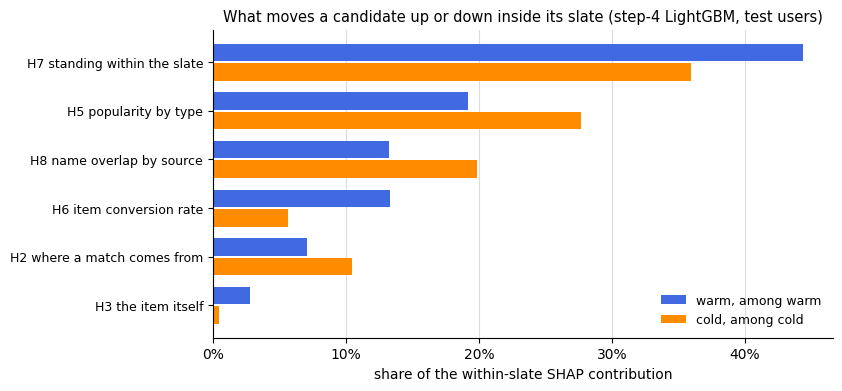

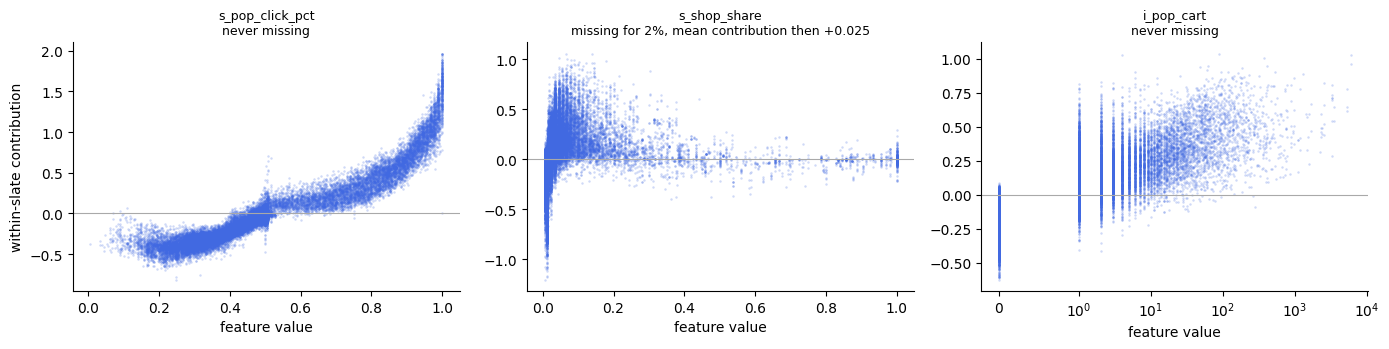

In [ ]:
EVAL_SLATES = np.flatnonzero(EVAL)
pick = np.sort(np.random.default_rng(SEED + 12).choice(EVAL_SLATES, min(CFG["shap_slates"], len(EVAL_SLATES)), replace=False))
rows = np.concatenate([np.arange(START[i], START[i] + LEN[i]) for i in pick])
XS = T[LGBM_FEATS].to_numpy(np.float32)[rows]
t0 = time.time()
contrib = LGBM.predict(XS, num_iteration=LGBM.best_iteration, pred_contrib=True)
assert np.allclose(contrib.sum(axis=1), SCORE["lgbm"][rows], atol=1e-4), "saved model does not reproduce step 4's test scores"
contrib = contrib[:, :-1]
starts = np.r_[0, np.cumsum(LEN[pick])[:-1]]
centred = contrib - np.repeat(np.add.reduceat(contrib, starts) / LEN[pick][:, None], LEN[pick], axis=0)
print(f"SHAP for {len(rows):,} candidates in {len(pick):,} test slates, {time.time() - t0:,.0f}s; contributions add up to the saved scores")

slate_of = np.repeat(np.arange(len(pick)), LEN[pick])
cold_r = COLD[rows]
sub_mean = pd.DataFrame(contrib).groupby(slate_of * 2 + cold_r).transform("mean").to_numpy()
among = contrib - sub_mean
SUBSETS = {"all candidates": (centred, np.ones(len(rows), bool)), "cold, among cold": (among, cold_r),
           "warm, among warm": (among, ~cold_r), "positives": (centred, POS[rows])}
feat = pd.DataFrame({s: np.abs(c[m]).mean(axis=0) for s, (c, m) in SUBSETS.items()}, index=LGBM_FEATS)
grp_idx = {g: [LGBM_FEATS.index(f) for f in GROUPS[g] if f in LGBM_FEATS] for g in KEPT}
grp = pd.DataFrame({s: {g: np.abs(c[m][:, ix].sum(axis=1)).mean() for g, ix in grp_idx.items()} for s, (c, m) in SUBSETS.items()})
grp = grp / grp.sum()
grp = grp.sort_values("all candidates", ascending=False)
feat["group"] = [GROUP_OF[f] for f in feat.index]
feat = feat.sort_values("all candidates", ascending=False)
save_csv(grp.reset_index(names="group"), "shap_groups")
save_csv(feat.reset_index(names="feature"), "shap_features")
show_result("Share of the within-slate SHAP contribution, by feature group", grp.style.format("{:.1%}"),
            note="Each column adds up to 100%. The cold and warm columns compare candidates only with others of the same kind in their slate.")
show_result("The 12 most influential features", feat.head(12).style.format({s: "{:.4f}" for s in SUBSETS}))
TOP3 = list(feat.index[:3])

### Figures
fig, ax = plt.subplots(figsize=(8, 0.5 * len(grp) + 1))
y = np.arange(len(grp))[::-1]
for off, s, col in ((0.2, "warm, among warm", COLOURS["lgbm"]), (-0.2, "cold, among cold", COLOURS["bar"])):
    ax.barh(y + off, grp[s], height=0.36, color=col, label=s)
ax.set_yticks(y)
ax.set_yticklabels(grp.index, fontsize=9)
ax.set_xlabel("share of the within-slate SHAP contribution")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(axis="x", color="gainsboro", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_title("What moves a candidate up or down inside its slate (step-4 LightGBM, test users)", fontsize=10.5)
save_fig(fig, "shap_groups")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
show = np.random.default_rng(SEED + 13).choice(len(rows), min(30_000, len(rows)), replace=False)
for ax, f in zip(axes, TOP3):
    j = LGBM_FEATS.index(f)
    v, c = XS[show, j], centred[show, j]
    ok = ~np.isnan(v)
    ax.scatter(v[ok], c[ok], s=3, alpha=0.25, color=COLOURS["lgbm"], linewidths=0)
    if ok.any() and (v[ok] >= 0).all() and v[ok].max() > 50 * max(np.median(v[ok]), 1.0):
        ax.set_xscale("symlog", linthresh=1)
    ax.axhline(0, color="darkgrey", lw=0.8)
    note = f"missing for {(~ok).mean():.0%}, mean contribution then {c[~ok].mean():+.3f}" if (~ok).any() else "never missing"
    ax.set_title(f"{f}\n{note}", fontsize=9)
    ax.set_xlabel("feature value")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("within-slate contribution")
fig.tight_layout()
save_fig(fig, "shap_dependence")
plt.show()

In [ ]:
trees = LGBM.trees_to_dataframe()
splits = trees[trees["split_feature"].notna()]
gain = splits.groupby("split_feature")["split_gain"].sum()
feat["share of split gain"] = (gain / gain.sum()).reindex(feat.index).fillna(0)
feat["SHAP rank"] = np.arange(1, len(feat) + 1)
feat["gain rank"] = feat["share of split gain"].rank(ascending=False, method="first").astype(int)
DAYS = [f for f in LGBM_FEATS if "_days_" in f]
cut_rows = []
for f in list(dict.fromkeys(DAYS[::-1] + TOP3)):
    part = splits[splits["split_feature"] == f]
    if part.empty:
        continue
    by_cut = part.groupby(part["threshold"].round(2))["split_gain"].sum().sort_values(ascending=False)
    cut_rows.append({"feature": f, "group": GROUP_OF[f], "splits": len(part), "share of split gain": part["split_gain"].sum() / gain.sum(),
                     "cut-points with most gain": ", ".join(f"{c:g}" for c in by_cut.index[:4]),
                     "missing values go": "never missing" if (part["missing_type"] != "NaN").all() else
                     "with the larger values" if part.loc[part["missing_direction"] == "right", "split_gain"].sum() > part["split_gain"].sum() / 2
                     else "with the smaller values"})
CUTS = pd.DataFrame(cut_rows).sort_values("share of split gain", ascending=False)
save_csv(CUTS, "tree_splits")
show_result("Split gain against SHAP rank for the 12 most influential features",
            feat.head(12)[["group", "all candidates", "share of split gain", "SHAP rank", "gain rank"]]
            .style.format({"all candidates": "{:.4f}", "share of split gain": "{:.1%}"}))
show_result("Where the trees cut the most-used features", CUTS.style.format({"share of split gain": "{:.1%}"}).hide(axis="index"),
            note="Cut-points of the days features are in days before the query. A row with a missing value follows the larger or the smaller side of each split.")

,group,all candidates,share of split gain,SHAP rank,gain rank
s_pop_click_pct,H7 standing within the slate,0.3250,54.1%,1,1
s_shop_share,H7 standing within the slate,0.2287,5.5%,2,4
i_pop_cart,H5 popularity by type,0.1822,4.5%,3,6
i_exposure_n,H5 popularity by type,0.1580,1.5%,4,8
ui_name_cov_recent,H8 name overlap by source,0.1337,12.4%,5,2
s_pop_order_pct,H7 standing within the slate,0.1126,6.5%,6,3
i_eng_rate_oof,H6 item conversion rate,0.0818,5.3%,7,5
i_pop_click,H5 popularity by type,0.0775,1.1%,8,9
ui_days_cate4_click,H2 where a match comes from,0.0385,0.7%,9,13
ui_days_shop_click,H2 where a match comes from,0.0249,1.0%,10,11


feature,group,splits,share of split gain,cut-points with most gain,missing values go
s_pop_click_pct,H7 standing within the slate,2074,54.1%,"0.8, 0.87, 0.86, 0.83",never missing
s_shop_share,H7 standing within the slate,2693,5.5%,"0.01, 0.02, 0.03, 0.04",with the smaller values
i_pop_cart,H5 popularity by type,1182,4.5%,"0, 4.5, 5.5, 9.5",never missing
ui_item_days_click,H3 the item itself,639,2.6%,"0, 0.66, 0.68, 0.55",with the smaller values
ui_item_days_cart,H3 the item itself,399,1.0%,"0, 86.62, 0.46, 0.88",with the smaller values
ui_days_shop_click,H2 where a match comes from,625,1.0%,"0, 4.59, 0.15, 5.74",with the larger values
ui_item_days_order,H3 the item itself,383,0.7%,"0, 6.24, 312.75, 23.68",with the smaller values
ui_days_cate4_click,H2 where a match comes from,828,0.7%,"0, 0.01, 6.01, 0.71",with the larger values
ui_days_shop_cart,H2 where a match comes from,514,0.7%,"0, 87.89, 86.12, 79.44",with the smaller values
ui_days_brand_click,H2 where a match comes from,523,0.3%,"0, 5.99, 1.08, 0.01",with the smaller values


## 6. Is "ordered this item before" a leak?
Step 2 found that candidates the user had ordered before are bought far more often than others (the 67x purchase lift of `ui_item_days_order`). One explanation is that people re-buy what they use up. Another, raised in the group, is that JD logged the test-day purchase into the history as well, so the feature would be reading the label. If that were so, the matching past order would usually be only minutes or hours old, because the history ends at the test query.

The first cell splits every test impression by the age of the user's last event on the same item, for each event type. The second cell (`blank_young`) treats an item as never ordered, carted or clicked whenever the user's latest such event on it is under a day old. A young event can reach the final model by five routes. The first two variants close three of them. The item's own "days since" feature (H3) is emptied, the user is taken out of the item's popularity count for that type (H5), and the within-slate popularity percentiles are re-ranked (H7). `ui_item_cart_no_order` is rebuilt from the changed columns. The third variant also closes the fourth route by emptying every shop, brand or category match under a day old (H2). The test users are then re-scored with the saved model (`rescore`) and the change in NDCG@10 gets a paired interval.

The check is harsher than the leak in one way and gentler in another. The features keep only the latest event's age, so emptying it also discards any older event of that type on the same item. Name overlap (H8), the fifth route, cannot be rebuilt from the feature rows, so it stays open. A small change therefore means the step-4 result does not rest on events that could be the test session, through every route except H8.

In [ ]:
AGE_WORD = "a day" if CFG["leak_days"] == 1 else f"{CFG['leak_days']:g} days"
AGE_EDGES = [0, 1 / 24, 1, 7, 30, 90, 365.01]
AGE_LABELS = ["under 1 hour", "1 hour to 1 day", "1 to 7 days", "7 to 30 days", "30 to 90 days", "90 to 365 days"]
base_pur, base_eng = (LABEL == 3).mean(), (LABEL > 0).mean()
leak_rows = []
for t in ("click", "cart", "order"):
    age = T[f"ui_item_days_{t}"].to_numpy()
    b = pd.cut(age, AGE_EDGES, labels=AGE_LABELS, right=False).astype(object)
    b = np.where(np.isnan(age), f"never {t}ed", b)
    for level in AGE_LABELS + [f"never {t}ed"]:
        m = b == level
        if m.sum() == 0:
            continue
        leak_rows.append({"same item, last": t, "age": level, "impressions": int(m.sum()), "share of impressions": m.mean(),
                          "engagement rate": (LABEL[m] > 0).mean(), "purchase rate": (LABEL[m] == 3).mean(),
                          "purchase lift": (LABEL[m] == 3).mean() / base_pur, "share of all purchases": (LABEL[m] == 3).sum() / (LABEL == 3).sum()})
LEAK = pd.DataFrame(leak_rows)
save_csv(LEAK, "leak_by_age")
with pd.option_context("display.max_rows", 50):
    show_result("Test impressions by the age of the user's last event on the same item", LEAK.style.format({"impressions": "{:,}", "share of impressions": "{:.2%}", "engagement rate": "{:.1%}",
                               "purchase rate": "{:.2%}", "purchase lift": "{:.1f}x", "share of all purchases": "{:.1%}"}).hide(axis="index"))

ordered = T["ui_item_days_order"].to_numpy()
bought = LABEL == 3
had_order = bought & ~np.isnan(ordered)
LEAK_FACTS = {"purchased candidates": int(bought.sum()),
              "purchased candidates the user had ordered before": had_order.sum() / bought.sum(),
              "of those, last order under 1 hour before the query": (ordered[had_order] < 1 / 24).mean(),
              "of those, last order under the cut-off": (ordered[had_order] < CFG["leak_days"]).mean(),
              "median age of that last order (days)": np.median(ordered[had_order]) if had_order.any() else np.nan,
              "purchase lift when the item was ordered before": (LABEL[~np.isnan(ordered)] == 3).mean() / base_pur}
FACT_FMT = {"purchased candidates": "{:,.0f}", "median age of that last order (days)": "{:.1f}", "purchase lift when the item was ordered before": "{:.1f}x"}
show_result("Repeat purchases and the age of the earlier order",
            pd.Series({k: "-" if pd.isna(v) else FACT_FMT.get(k, "{:.1%}").format(v) for k, v in LEAK_FACTS.items()}, name="test users").to_frame(),
            note=f"The cut-off is {AGE_WORD}.")

"same item, last",age,impressions,share of impressions,engagement rate,purchase rate,purchase lift,share of all purchases
click,under 1 hour,"4,652",0.30%,29.7%,2.52%,18.1x,5.4%
click,1 hour to 1 day,"1,621",0.10%,23.6%,0.93%,6.6x,0.7%
click,1 to 7 days,"2,333",0.15%,18.2%,0.94%,6.8x,1.0%
click,never clicked,"1,558,418",99.45%,1.9%,0.13%,0.9x,92.9%
cart,under 1 hour,"1,288",0.08%,28.3%,5.82%,41.8x,3.4%
cart,1 hour to 1 day,573,0.04%,25.3%,1.92%,13.8x,0.5%
cart,1 to 7 days,905,0.06%,19.7%,1.22%,8.7x,0.5%
cart,7 to 30 days,"1,266",0.08%,21.7%,2.21%,15.9x,1.3%
cart,30 to 90 days,"1,226",0.08%,21.1%,2.12%,15.2x,1.2%
cart,never carted,"1,561,766",99.66%,2.0%,0.13%,0.9x,93.1%


,test users
purchased candidates,"2,181"
purchased candidates the user had ordered before,6.0%
"of those, last order under 1 hour before the query",17.7%
"of those, last order under the cut-off",22.3%
median age of that last order (days),57.8
purchase lift when the item was ordered before,69.5x


In [ ]:
def rescore(change):
    """change(X) edits a copy of the test features in place and returns how many values it emptied or scaled."""
    X = T[LGBM_FEATS].copy()
    n_changed = change(X)
    s = np.empty(len(X), np.float32)
    for i in range(0, len(X), 2_000_000):
        s[i:i + 2_000_000] = LGBM.predict(X.iloc[i:i + 2_000_000].to_numpy(np.float32), num_iteration=LGBM.best_iteration)
    return J.evaluate(USER, LABEL, s, COLD, seed=SEED), n_changed

def compare(label, df, n):
    """One row with the change, how many values it emptied or scaled, and its paired effect against the saved LightGBM."""
    row = {"change": label, "values emptied": n, "NDCG@10": df["ndcg@10"].mean()}
    for m, name in (("ndcg@10", "NDCG@10 change"), ("purchase_recall@10", "purchase Recall@10 change")):
        d = J.paired(df, PS["lgbm"], m, n_boot=N_BOOT, seed=SEED)
        row[name], row[f"{name} lo"], row[f"{name} hi"] = d["diff"], d["lo"], d["hi"]
    return row

POP_OF = {"click": "i_pop_click", "cart": "i_pop_cart", "order": "i_pop_order"}
PCT_OF = {"click": "s_pop_click_pct", "order": "s_pop_order_pct"}

def blank_young(types, days=CFG["leak_days"], matches=False):
    def change(X):
        n = 0
        for t in types:
            col = f"ui_item_days_{t}"
            if col not in X:
                continue
            m = (X[col] < days).to_numpy()
            n += int(m.sum())
            X.loc[m, col] = np.nan
            if POP_OF[t] in X:
                X.loc[m, POP_OF[t]] = np.maximum(X.loc[m, POP_OF[t]] - 1, 0)
                if PCT_OF.get(t) in X:
                    X[PCT_OF[t]] = X[POP_OF[t]].groupby(USER).rank(pct=True).astype(np.float32)
        if matches:
            for col in [c for c in X if c.startswith("ui_days_")]:
                m = (X[col] < days).to_numpy()
                n += int(m.sum())
                X.loc[m, col] = np.nan
        if "ui_item_cart_no_order" in X:
            X["ui_item_cart_no_order"] = (X["ui_item_days_cart"].notna() & ~(X["ui_item_days_order"] <= X["ui_item_days_cart"])).astype(np.float32)
        return n
    return change

def show_changes(title, table):
    fmt = {"values emptied": "{:,}", "values scaled": "{:,}", "NDCG@10": "{:.4f}"} | {c: "{:+.4f}" for c in table.columns if "change" in c and c != "change"}
    show_result(title, mark(table.style.format(fmt), table, ["NDCG@10 change", "purchase Recall@10 change"]).hide(axis="index"),
                note="Paired against the step-4 LightGBM as saved, over the same test slates. Green marks an interval above zero and red one below zero.")

t0 = time.time()
LEAK_SENS = pd.DataFrame([compare(label, *rescore(blank_young(types, matches=matches))) for label, types, matches in (
    (f"orders of the same item under {AGE_WORD} old removed (H3, H5, H7)", ["order"], False),
    (f"every same-item click, cart or order under {AGE_WORD} old removed (H3, H5, H7)", ["click", "cart", "order"], False),
    (f"as above, plus every shop, brand or category match under {AGE_WORD} old (H2)", ["click", "cart", "order"], True))])
print(f"re-scored {len(LEAK_SENS)} variants in {time.time() - t0:,.0f}s")
show_changes("Test results without the youngest same-item events", LEAK_SENS)

re-scored 3 variants in 106s


change,values emptied,NDCG@10,NDCG@10 change,NDCG@10 change lo,NDCG@10 change hi,purchase Recall@10 change,purchase Recall@10 change lo,purchase Recall@10 change hi
"orders of the same item under a day old removed (H3, H5, H7)",99,0.4219,-0.0001,-0.0003,+0.0000,+0.0000,+0.0000,+0.0000
"every same-item click, cart or order under a day old removed (H3, H5, H7)","8,233",0.4124,-0.0096,-0.0111,-0.0084,-0.0005,-0.0019,+0.0014
"as above, plus every shop, brand or category match under a day old (H2)","824,211",0.4017,-0.0204,-0.0224,-0.0185,-0.0092,-0.0148,-0.0036


## 7. Are the larger out-of-fold counts for validation and test users a problem?
The item conversion features (group H6) are built from other training users' outcomes. A training user's row may only use the four folds it is not in, while a validation or test row uses all five, because none of their labels are in the folds. So `i_label_imps_oof`, the number of training impressions behind an item's rates, is larger for validation and test rows, which is the gap noticed in the group. If an item has N training impressions, a test row sees all N, while a training row loses its own fold, and that fold always contains the row itself. The training row therefore expects 0.8 × (N − 1), so the ratio is a little above 5/4 = 1.25, and well above it for the many items with only a few impressions. The rates are smoothed towards the overall rate with a prior worth 20 impressions, so a larger count also moves a test row's rate a little further from the prior. A training row's rate is also empty more often, whenever only its own fold saw the item.

The first cell measures both gaps on the items seen by training and test rows. The second scales the test counts by 0.8 to put them on the training scale, re-scores with the saved model and measures the change.

In [ ]:
split_code = split_users.set_index("user_id")["split"]
per_item = {}
for f in fparts:
    d = pd.read_parquet(f, columns=["user_id", "wid", "i_label_imps_oof", "i_eng_rate_oof"])
    d["split"] = split_code.reindex(d["user_id"].to_numpy()).to_numpy()
    d = d[d["split"].isin(["train", "test"])]
    d["empty"] = d["i_eng_rate_oof"].isna()
    g = d.groupby(["split", "wid"]).agg(imps=("i_label_imps_oof", "sum"), empty=("empty", "sum"), rows=("empty", "size"))
    for s in ("train", "test"):
        if s in g.index.get_level_values(0):
            per_item.setdefault(s, []).append(g.loc[s])
del d, g
per_item = {s: pd.concat(v).groupby(level=0).sum() for s, v in per_item.items()}
both = per_item["train"].index.intersection(per_item["test"].index)
tr, te = per_item["train"].loc[both], per_item["test"].loc[both]
n_test, n_train = te["imps"] / te["rows"], tr["imps"] / tr["rows"]
keep = (n_train > 0) & (n_test > 1)
OOF_RATIO = n_test[keep].sum() / n_train[keep].sum()
OOF_ADJ = n_train[keep].sum() / (0.8 * (n_test[keep] - 1)).sum()
OOF_EMPTY = {"train": tr["empty"].sum() / tr["rows"].sum(), "test": te["empty"].sum() / te["rows"].sum()}
show_result("Out-of-fold counts on items seen by both training and test rows", pd.DataFrame({
    "items": [f"{keep.sum():,}"], "test count / training count": [f"{OOF_RATIO:.3f}"],
    "training count / expected 0.8 x (test count - 1)": [f"{OOF_ADJ:.3f}"],
    "rows with an empty rate, training": [f"{OOF_EMPTY['train']:.1%}"], "rows with an empty rate, test": [f"{OOF_EMPTY['test']:.1%}"]}).style.hide(axis="index"),
    note="A test row counts all N training impressions of the item. A training row drops its own fold, which always holds the row itself, so it expects 0.8 x (N - 1). A value near 1 in the third column means the gap is the fold design.")

items,test count / training count,training count / expected 0.8 x (test count - 1),"rows with an empty rate, training","rows with an empty rate, test"
"412,651",1.424,1.010,7.2%,0.0%


In [ ]:
def shrink(X):
    X["i_label_imps_oof"] = X["i_label_imps_oof"] * 0.8
    return int(X["i_label_imps_oof"].notna().sum())

OOF_SENS = pd.DataFrame([compare("test impression counts scaled by 0.8 (the training scale)", *rescore(shrink))]) if "i_label_imps_oof" in LGBM_FEATS else pd.DataFrame()
OOF_SENS = OOF_SENS.rename(columns={"values emptied": "values scaled"})
if len(OOF_SENS):
    show_changes("Test results with the out-of-fold counts on the training scale", OOF_SENS)
SENS_T = pd.concat([LEAK_SENS, OOF_SENS], ignore_index=True)
save_csv(SENS_T, "sensitivity")

change,values scaled,NDCG@10,NDCG@10 change,NDCG@10 change lo,NDCG@10 change hi,purchase Recall@10 change,purchase Recall@10 change lo,purchase Recall@10 change hi
test impression counts scaled by 0.8 (the training scale),"1,567,024",0.4219,-0.0001,-0.0004,+0.0002,+0.0005,-0.0014,+0.0024


## 8. Business ideas, tested
The diagnostics suggest three changes JD could make to how results are served. Each is scored here on the test slates it changes, with a paired interval against the step-4 LightGBM on those same slates, before section 9 states anything as an insight. Pairing over every slate would dilute the effect with slates the change never touches. The table also gives the change averaged over all slates, which is what JD would see overall.

1. **Popularity where the model has nothing personal to read.** Serve the popularity order on slates the user's history does not touch, or to users with no clicks in the last 7 days, and LightGBM elsewhere. If NDCG@10 on those slates does not measurably change, the model can be skipped for those requests.
2. **A buy-again rule.** Move every candidate the user ordered before, or carted and has not ordered since, to the top of the slate, keeping LightGBM's order among them and below them.
3. **How much of the gap cold items cause.** The last table gives the share of the total NDCG@10 shortfall (one minus NDCG@10, summed over slates) that comes from slates whose positives are all cold. It sizes the cold-start problem instead of testing a fix.

In [ ]:
no_touch = ~SL["own_any"].to_numpy()
no_click = SL["u_n_click_w"].fillna(0).to_numpy() == 0
again = (T["ui_item_days_order"].notna() | (T["ui_item_cart_no_order"] == 1)).to_numpy()
again_slate = np.maximum.reduceat(again.astype(np.int8), START) > 0
POLICIES = [
    ("popularity order on slates the history does not touch", np.where(np.repeat(no_touch, LEN), SCORE["pop"], SCORE["lgbm"]), no_touch),
    ("popularity order for users with no clicks in 7 days", np.where(np.repeat(no_click, LEN), SCORE["pop"], SCORE["lgbm"]), no_click),
    ("buy again, past orders and open carts moved to the top", SCORE["lgbm"] + 1e3 * again, again_slate),
]
bus_rows = []
for label, score, affected in POLICIES:
    df = J.evaluate(USER, LABEL, score, COLD, seed=SEED)
    row = {"change": label, "slates changed": int((affected & EVAL).sum()), "share of slates": (affected & EVAL).sum() / EVAL.sum()}
    for m, name in (("ndcg@10", "NDCG@10 change on them"), ("purchase_recall@10", "purchase Recall@10 change on them")):
        d = J.paired(df.loc[affected], PS["lgbm"].loc[affected], m, n_boot=N_BOOT, seed=SEED)
        row[name], row[f"{name} lo"], row[f"{name} hi"] = d["diff"], d["lo"], d["hi"]
    row["NDCG@10 change over all slates"] = df["ndcg@10"].mean() - PS["lgbm"]["ndcg@10"].mean()
    bus_rows.append(row)
BUS = pd.DataFrame(bus_rows)
save_csv(BUS, "business_tests")
show_result("Three serving changes, scored on the test slates they change", mark(BUS.style.format(
    {"slates changed": "{:,}", "share of slates": "{:.1%}"} | {c: "{:+.4f}" for c in BUS.columns if "change " in c}, na_rep="-"), BUS,
    ["NDCG@10 change on them", "purchase Recall@10 change on them"]).hide(axis="index"),
    note="Paired against the step-4 LightGBM on the slates each change affects. Green marks an interval above zero and red one below zero.")

shortfall = 1 - PS["lgbm"]["ndcg@10"].to_numpy()
COLD_GAP = {"slates whose positives are all cold": cold_only.sum() / EVAL.sum(),
            "their share of the NDCG@10 shortfall": np.nansum(shortfall[cold_only]) / np.nansum(shortfall[EVAL]),
            "their NDCG@10": np.nanmean(nd["lgbm"][cold_only]) if cold_only.any() else np.nan,
            "NDCG@10 of the other slates": np.nanmean(nd["lgbm"][EVAL & ~cold_only])}
show_result("How much of the gap comes from slates where only cold items were wanted",
            pd.Series({k: f"{v:.1%}" if "slates whose" in k or "share" in k else f"{v:.4f}" for k, v in COLD_GAP.items()}).to_frame("test"))

change,slates changed,share of slates,NDCG@10 change on them,NDCG@10 change on them lo,NDCG@10 change on them hi,purchase Recall@10 change on them,purchase Recall@10 change on them lo,purchase Recall@10 change on them hi,NDCG@10 change over all slates
popularity order on slates the history does not touch,"12,345",71.4%,-0.0360,-0.0396,-0.0326,-0.0383,-0.0576,-0.0194,-0.0257
popularity order for users with no clicks in 7 days,"2,820",16.3%,-0.0467,-0.0549,-0.0391,-0.0916,-0.1305,-0.0531,-0.0076
"buy again, past orders and open carts moved to the top","3,023",17.5%,-0.0061,-0.0098,-0.0022,+0.0010,+0.0000,+0.0031,-0.0011


,test
slates whose positives are all cold,14.9%
their share of the NDCG@10 shortfall,22.7%
their NDCG@10,0.1225
NDCG@10 of the other slates,0.4746


## 9. What the numbers say
The table below collects the key numbers from sections 2 to 8 in one place.

In [ ]:
def ci(d, col):
    return f"{d[col]:+.4f} [{d[col + ' lo']:+.4f}, {d[col + ' hi']:+.4f}]"

pre = SEG[SEG["segment"] != "best outcome (reads labels)"]
row = lambda segment, group: SEG[(SEG["segment"] == segment) & (SEG["group"] == group)].iloc[0]
top10 = lambda segment, group: ITEMS[(ITEMS["segment"] == segment) & (ITEMS["group"] == group)]["top 10: " + NAMES["lgbm"]].iloc[0]
bus = BUS.set_index("change")
ANYONE = "item in anyone's history"
KEY = {
    "test slates with a positive": f"{EVAL.sum():,}",
    "user groups where LightGBM beats the bar / beats popularity (interval above zero)":
        f"{(pre['LightGBM minus bar lo'] > 0).sum()} of {len(pre)} / {(pre['LightGBM minus popularity lo'] > 0).sum()} of {len(pre)}",
    "user groups where the attention ranker beats LightGBM": int((pre["attention minus LightGBM lo"] > 0).sum()),
    "NDCG@10, history touches / does not touch a candidate":
        f"{row('history touches a candidate', 'yes')[NAMES['lgbm']]:.4f} / {row('history touches a candidate', 'no')[NAMES['lgbm']]:.4f}",
    "NDCG@10, no clicks in 7 days / 50 or more":
        f"{row('clicks in the last 7 days', 'none')[NAMES['lgbm']]:.4f} / {row('clicks in the last 7 days', '50 or more')[NAMES['lgbm']]:.4f}",
    "positives in the top 10, ordered before / clicked before / nothing in history":
        f"{top10('past contact with the item', 'ordered before'):.0%} / {top10('past contact with the item', 'clicked before'):.0%} / "
        f"{top10('past contact with the item', 'nothing in the history'):.0%}",
    "positives in the top 10, warm / cold": f"{top10(ANYONE, 'warm'):.0%} / {top10(ANYONE, 'cold (no one)'):.0%}",
    "failed slates (no positive in the top 10)": f"{FAIL.sum() / EVAL.sum():.1%}",
    "most common failure cause": f"{cause_t['share of failed slates'].idxmax()} ({cause_t['share of failed slates'].max():.0%})",
    "failed slates where the bar and popularity also fail": f"{((nd['bar'][FAIL] == 0) & (nd['pop'][FAIL] == 0)).mean():.0%}",
    "top two feature groups (share of within-slate contribution)":
        f"{grp.index[0]} {grp['all candidates'].iloc[0]:.0%}, {grp.index[1]} {grp['all candidates'].iloc[1]:.0%}",
    "top feature group among cold items": f"{grp['cold, among cold'].idxmax()} {grp['cold, among cold'].max():.0%}",
    "purchases of items ordered before": f"{LEAK_FACTS['purchased candidates the user had ordered before']:.1%}",
    "of those, last order under the cut-off / median age (days)":
        f"{LEAK_FACTS['of those, last order under the cut-off']:.1%} / {LEAK_FACTS['median age of that last order (days)']:.1f}",
    "NDCG@10 change with every route but H8 closed": ci(LEAK_SENS.iloc[-1], "NDCG@10 change"),
    "out-of-fold ratio, raw / against 0.8 x (N - 1)": f"{OOF_RATIO:.2f} / {OOF_ADJ:.2f}",
    "NDCG@10 change with test counts on the training scale": ci(OOF_SENS.iloc[0], "NDCG@10 change") if len(OOF_SENS) else "-",
    **{f"policy: {k} (NDCG@10 change on the slates it changes)": f"{ci(r, 'NDCG@10 change on them')}, {r['share of slates']:.0%} of slates"
       for k, r in bus.iterrows()},
    "slates whose positives are all cold / their share of the shortfall":
        f"{COLD_GAP['slates whose positives are all cold']:.0%} / {COLD_GAP['their share of the NDCG@10 shortfall']:.0%}",
}
KEY = pd.Series(KEY, name="value").to_frame()
save_csv(KEY.reset_index(names="finding"), "key_numbers")
with pd.option_context("display.max_colwidth", 200):
    show_result("Key numbers behind the summary", KEY)

,value
test slates with a positive,"17,297"
user groups where LightGBM beats the bar / beats popularity (interval above zero),17 of 19 / 19 of 19
user groups where the attention ranker beats LightGBM,0
"NDCG@10, history touches / does not touch a candidate",0.4996 / 0.3909
"NDCG@10, no clicks in 7 days / 50 or more",0.3996 / 0.4135
"positives in the top 10, ordered before / clicked before / nothing in history",99% / 98% / 45%
"positives in the top 10, warm / cold",65% / 14%
failed slates (no positive in the top 10),26.9%
most common failure cause,history touches no candidate (44%)
failed slates where the bar and popularity also fail,81%


### Summary

**Reproduction.** Re-evaluating the saved scores reproduces every model's per-slate results from steps 3 and 4, so the 17,297 test slates with a positive analysed here are the ones the report quotes.

**By user.** The step-4 LightGBM beats the interim bar in 17 of the 19 user groups and popularity in all 19, each with a 95% interval above zero. Its gain over the bar is largest on slates the user's history touches (+0.0238 NDCG@10) and is not measurable on slates of 31 to 60 candidates or on slates that are at least three-quarters cold. The attention ranker is never measurably better than LightGBM in any group, and is measurably worse in 11 of the 19.

**History.** Personal history is where the model earns its keep. On the 29% of slates where the user's history touches a candidate, NDCG@10 is 0.500 against 0.391 elsewhere, and LightGBM beats popularity by +0.189 there against +0.036 on the rest. Recent activity matters less than expected, since users with no clicks in the last 7 days score 0.400 against 0.413 for users with 50 or more.

**By item.** Almost every positive the user had already ordered, carted or clicked reaches the top 10 (98 to 99%). For positives with nothing in the history the rate falls to 45%, and for cold positives to 14%, which is no better than the 15% a random order would give. Popularity places only 7% of cold positives in the top 10. Positives shown in over 100 slates reach the top 10 93% of the time, against 23% for items shown in a single slate.

**Failures.** In 26.9% of slates with a positive, no positive reaches the top 10. Most of these have one of two causes, either the user's history touches no candidate (44%) or every positive is cold (40%), and only 9% are near misses ranked 11 to 20. The bar and popularity both fail on 81% of these slates, so they are hard for every model rather than mistakes particular to LightGBM.

**What drives the ranking.** Standing within the slate (H7) accounts for 44% of the within-slate SHAP contribution and popularity by type (H5) for 26%. One feature, the item's click-popularity percentile within its slate (`s_pop_click_pct`), takes 54% of the trees' split gain, and the trees cut it mostly between 0.80 and 0.87, so the model's first question is whether an item sits in the top fifth of its slate by recent clicks. Among cold items H7 still leads (36%), followed by H5 (28%) and name overlap, H8 (20%).

**Leak check.** Of the purchased test candidates, 6.0% had been ordered by the user before, and 22.3% of those orders were under a day old (median age 57.8 days). Treating orders under a day old as never placed changes NDCG@10 by -0.0001 (95% -0.0003 to +0.0000), so the 67x "ordered before" signal does not depend on orders that could be the test purchase logged twice. Very recent activity in general does matter. Removing every same-item click, cart or order under a day old lowers NDCG@10 by 0.0096 (95% 0.0084 to 0.0111), and also removing shop, brand and category matches under a day old lowers it by 0.0204 (95% 0.0185 to 0.0224). Items the user clicked under an hour before the query are engaged with 30% of the time, against 2% for items never clicked. The data cannot tell whether these events belong to the same session as the test query or to an earlier one, so the report should state that about a twentieth of the step-4 score (0.020 of 0.422) rests on activity in the last day before the query.

**Out-of-fold counts.** Test rows count 1.42 times as many training impressions as training rows on the same items, and training rows hold 1.01 times the 0.8 × (N − 1) that the five-fold design predicts, so the gap comes from the fold design and not from a leak. Rescaling the test counts to the training level changes NDCG@10 by -0.0001 (95% -0.0004 to +0.0002), so the gap does not affect the model.

### What this means for JD

**Run the model for everyone.** Serving the popularity order instead of LightGBM on the 71% of slates the user's history does not touch lowers NDCG@10 on those slates by 0.036 (95% 0.033 to 0.040), and for users with no clicks in the last week (16% of slates) by 0.047 (95% 0.039 to 0.055). The model is worth running even where it has no personal history to read.

**No separate buy-again rule.** Repeat purchases are 6% of test purchases, and the model already puts 99% of previously ordered positives in the top 10. Forcing past orders and open carts to the top of the slate lowers NDCG@10 on the 17% of slates that hold one by 0.006 (95% 0.002 to 0.010).

**Cold items are the gap to close.** Cold items are 56.5% of test impressions. Slates where only cold items were wanted are 15% of slates but 23% of the total shortfall, and cold positives reach the top 10 no more often than chance. Better content signals for new products, such as fuller use of their names and categories, are where the next gain would come from.


## 10. Outputs of this notebook
The tables are in `processed/results/` and the figures in `processed/results/figures/`.

In [ ]:
for folder in (PATHS["results"], PATHS["figures"]):
    for f in sorted(glob.glob(os.path.join(folder, "step5_*.*"))):
        print(f"{os.path.relpath(f, BASE):<62} {os.path.getsize(f) / 1e6:>8,.1f} MB")

processed/results/step5_business_tests.csv                          0.0 MB
processed/results/step5_failure_causes.csv                          0.0 MB
processed/results/step5_failures.csv                                0.0 MB
processed/results/step5_item_segments.csv                           0.0 MB
processed/results/step5_key_numbers.csv                             0.0 MB
processed/results/step5_leak_by_age.csv                             0.0 MB
processed/results/step5_sensitivity.csv                             0.0 MB
processed/results/step5_shap_features.csv                           0.0 MB
processed/results/step5_shap_groups.csv                             0.0 MB
processed/results/step5_tree_splits.csv                             0.0 MB
processed/results/step5_user_segments.csv                           0.0 MB
processed/results/figures/step5_item_segments.png                   0.1 MB
processed/results/figures/step5_shap_dependence.png                 0.3 MB
processed/results/figures

## 11. AI interaction log
| Core prompt and task objective | AI output summary | Critical evaluation | Refinement and final action |
|---|---|---|---|
| I told the model what I wanted to test or analyse in natural language| The proposed code that achieves the intended desired outcome | The code returned is not necessarily right, so I independently reviewed it before choosing which lines to keep and omit. | Kept every line that made sense to me in achieving the intended outcome |
| Asked the AI model if my final takeaways and conclusions were comprehensive or if there were hidden insights and numbers that I could produce to enrich the summary | Produced several suggestions on areas lacking such as out of fold counts | Confirmed by running the numbers and evaluations | Added those enriched insights in |
| Ask a fresh AI reviewer to find correctness errors against steps 2 to 4. | The leak check missed the popularity route (H5, H7 count the user's own orders), the out-of-fold yardstick of 1.25 was wrong, and cold-item SHAP was misleading. | Checked each against step 2's code. A simulation confirmed that 1.25 would flag correct data as a bug. | Closed the popularity route, compared counts with 0.8 × (N − 1) instead, and centred cold SHAP among cold items. |
| Ask a second AI reviewer to grade the notebook against the guideline. | Insights were asserted, not tested, and the failure analysis and interpretation were thin. | Agreed with most points. Skipped a formal multiple-testing correction and stated the per-group caveat instead. | Added tested business ideas (section 8), failure causes, the trees' cut-points and highlighted results. |
| Ask a third AI reviewer, with no earlier context, to re-check the revised notebook. | The section 8 tests were diluted by slates a policy never touches, and some summary sentences could overclaim. | Confirmed by running it. | Paired each policy only on the slates it changes and tied every sentence to its result. |
